# ENEMDU sintética · proyecto reproducible
Este notebook solo **orquesta**: la lógica vive en `src/`.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.datos import generar_enemdu
from src.limpieza import limpiar, agregar_variables
from src.anonimizar import anonimizar, k_anonimato

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
SEMILLA = 42

## Parte 1 · Estructura y datos crudos (Ejercicio 1.1)

In [2]:
for carpeta in ["data/crudos", "data/procesados", "notebooks", "src", "reportes"]:
    (RAIZ / carpeta).mkdir(parents=True, exist_ok=True)

df = generar_enemdu()
df.to_csv(RAIZ / "data/crudos/enemdu.csv", index=False)
print(df.shape)

(4025, 11)


## Parte 2 · Funciones importadas desde `src` (Ejercicio 2.2)

In [3]:
crudo = pd.read_csv(RAIZ / "data/crudos/enemdu.csv")
limpio = agregar_variables(limpiar(crudo))
limpio.to_csv(RAIZ / "data/procesados/enemdu_limpio.csv", index=False)

print(f"{len(crudo)} filas crudas -> {len(limpio)} limpias")
limpio[["ingreso", "log_ingreso", "edad", "grupo_edad"]].head()

4025 filas crudas -> 3790 limpias


,ingreso,log_ingreso,edad,grupo_edad
0,213.81,5.37,52,45-65
1,665.82,6.50,55,45-65
2,594.50,6.39,27,18-29
3,"1,020.65",6.93,63,45-65
4,212.32,5.36,19,18-29


## Parte 3 · Semillas (Ejercicio 3.1)

In [4]:
print("Sin semilla:")
print(df.sample(3).index.tolist())
print(df.sample(3).index.tolist())
print("Con random_state=SEMILLA:")
print(df.sample(3, random_state=SEMILLA).index.tolist())
print(df.sample(3, random_state=SEMILLA).index.tolist())

Sin semilla:
[2396, 1328, 308]
[2338, 3640, 1873]
Con random_state=SEMILLA:
[1718, 1204, 2722]
[1718, 1204, 2722]


Sin semilla, cada ejecución devuelve filas distintas: el generador parte de un estado
aleatorio diferente. Con `random_state=SEMILLA` el generador arranca siempre del mismo
estado y devuelve **las mismas filas**, en esta máquina y en la de cualquier colega
(con las mismas versiones de librerías, por eso importa `requirements.txt`).

## Vistazo rápido a la pregunta de análisis

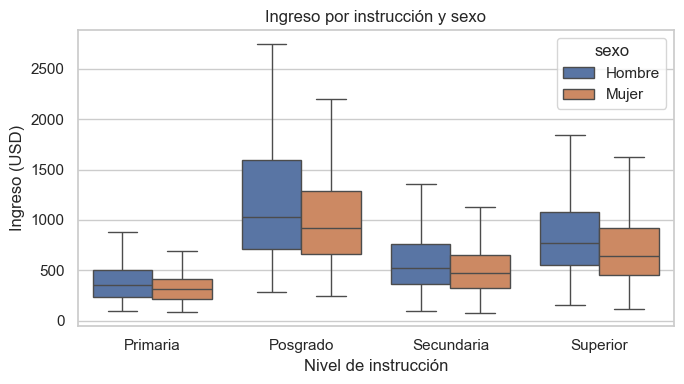

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=limpio, x="nivel_instruccion", y="ingreso", hue="sexo", ax=ax, showfliers=False)
ax.set(xlabel="Nivel de instrucción", ylabel="Ingreso (USD)", title="Ingreso por instrucción y sexo")
fig.tight_layout()
fig.savefig(RAIZ / "reportes/ingreso_instruccion_sexo.png", dpi=150)

## Parte 5 · Anonimización según la LOPDP (Ejercicio 5.1)

In [6]:
rng = np.random.default_rng(SEMILLA)
personal = df.drop_duplicates("id_persona").head(1500).copy()
personal["cedula"] = [f"{rng.integers(1, 25):02d}{rng.integers(0, 10**8):08d}" for _ in range(len(personal))]  # ficticias
personal["nombre"] = rng.choice(["Ana", "Luis", "María", "Jorge", "Carla", "Diego", "Sofía", "Pablo"], len(personal)) + " " + \
                     rng.choice(["Pérez", "Guerrero", "Andrade", "Zambrano", "Vera", "Mora", "Salazar"], len(personal))
personal["fecha_nac"] = pd.to_datetime("2026-01-01") - pd.to_timedelta(personal["edad"] * 365 + rng.integers(0, 365, len(personal)), unit="D")
personal[["cedula", "nombre", "fecha_nac", "provincia", "edad", "ingreso"]].head()

,cedula,nombre,fecha_nac,provincia,edad,ingreso
0,0377395604,María Pérez,1973-05-01,Pichincha,52,213.81
1,1643887843,Carla Vera,1970-04-10,El Oro,55,665.82
2,1185859791,Ana Mora,1998-01-27,Azuay,27,594.50
3,0369736802,Ana Pérez,1962-10-19,Guayas,63,"1,020.65"
4,0509417734,Pablo Zambrano,2006-12-04,Guayas,19,212.32


In [7]:
import os
# La sal se lee de una variable de entorno; nunca se escribe en el notebook.
SAL = os.environ.get("LOPDP_SAL") or input("Sal secreta: ")

anon = anonimizar(personal, SAL)
anon.to_csv(RAIZ / "data/procesados/enemdu_anonimizada.csv", index=False)
anon[["id_seudonimo", "provincia", "edad", "sexo", "ingreso"]].head()

,id_seudonimo,provincia,edad,sexo,ingreso
0,a6605d45f298,Pichincha,50-59,Hombre,210.00
1,2e52f82889f5,El Oro,50-59,Hombre,670.00
2,4344979c6e7d,Azuay,20-29,Hombre,590.00
3,3f698784a99f,Guayas,60-69,Mujer,"1,020.00"
4,092156b15e34,Guayas,10-19,Mujer,210.00


In [8]:
assert not {"nombre", "fecha_nac", "cedula"} & set(anon.columns)
assert anon["id_seudonimo"].nunique() == personal["cedula"].nunique()   # sin colisiones
print("k-anonimato (provincia, edad, sexo):", k_anonimato(anon, ["provincia", "edad", "sexo"]))
anon.groupby(["provincia", "edad", "sexo"]).size().sort_values().head()

k-anonimato (provincia, edad, sexo): 1


provincia   edad   sexo  
Azuay       10-19  Mujer     1
Chimborazo  10-19  Hombre    1
El Oro      10-19  Hombre    1
Chimborazo  60-69  Mujer     1
Galápagos   30-39  Hombre    1
dtype: int64

### Limitaciones
- **Seudonimizar no es anonimizar.** Quien tenga la sal puede recalcular el hash de
  cualquier cédula y reidentificar a la persona; además, las cédulas tienen un espacio
  pequeño (2 dígitos de provincia + 8), así que sin sal serían reversibles por fuerza
  bruta. Por eso la sal es secreta y se guarda fuera del repositorio.
- **Riesgo residual por cuasi-identificadores.** Provincia + rango de edad + sexo dejan
  grupos de tamaño 1 (p. ej., en Galápagos): esa persona es única y su ingreso queda
  expuesto. Antes de publicar convendría agrupar provincias poco pobladas por región o
  suprimir celdas pequeñas hasta alcanzar un k mínimo (p. ej., k ≥ 5).
- `id_persona` es un identificador interno que permite volver a unir con la tabla
  original; si la tabla se comparte fuera del equipo, también debería eliminarse.